# Week 8 — Disagreement Correlates: Annotator Profiles & Linguistic Features (ELFEN)

Two questions from the supervisor meeting:

1. **Annotator side:** Is there a correlation between annotator profiles (demographics + psychological factors) and their *agreement patterns*?
2. **Prompt side:** Which linguistic features of a prompt (emotion, psycholinguistic, readability, …), extracted with **ELFEN**, are associated with disagreement? Which are the most important?

Conventions kept from the main report: `Harm_Level` is never used as a feature, prompt split = `np.random.seed(42)` shuffle (100 train / 50 test), `KFold(n_splits=5, shuffle=True, random_state=42)`, `Ridge(alpha=1.0)`.

**Setup (in the ELFEN venv):**
```
pip install elfen pandas scipy scikit-learn matplotlib
python -m spacy download en_core_web_sm
```
Run this notebook from the `notebooks/` folder of the repo.

In [26]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, false_discovery_control
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')

ROOT = '..'                       # repo root (notebook lives in notebooks/)
sys.path.insert(0, ROOT)
from src.data_loader import encode_demographics

DATA = os.path.join(ROOT, 'data')
OUT  = os.path.join(ROOT, 'outputs')
os.makedirs(OUT, exist_ok=True)

KF = KFold(n_splits=5, shuffle=True, random_state=42)

prompts = pd.read_csv(os.path.join(DATA, 'prompts.csv'))
ann     = pd.read_csv(os.path.join(DATA, 'annotations.csv'))
RATING_COLS = [f'Rating_{i}' for i in range(1, 151)]
R = ann[RATING_COLS].to_numpy(dtype=float)       # 100 x 150, NaN = missing
print(prompts.shape, ann.shape)

(150, 65) (100, 314)


## Part A — Annotator profiles vs. agreement patterns

For each annotator *i* we compare their ratings with the **leave-one-out consensus** (mean of the other 99 annotators on each prompt), using only the prompts they rated:

- **agreement** = Spearman ρ between annotator *i*'s ratings and the consensus (does the annotator *rank* prompts like everyone else?)
- **MAD** = mean absolute deviation from the consensus, in rating points (how far off are they on average?)
- **bias** = mean signed deviation (do they rate systematically higher/lower?) — descriptive only

Then each profile feature (encoded with `encode_demographics`, plus Factor_1–3) is correlated with agreement and MAD (Spearman), with Benjamini–Hochberg FDR correction over all tests.

In [27]:
agree, mad, bias, n_rated = [], [], [], []
for i in range(R.shape[0]):
    consensus = np.nanmean(np.delete(R, i, axis=0), axis=0)
    m = ~np.isnan(R[i])
    agree.append(spearmanr(R[i, m], consensus[m]).correlation)
    mad.append(np.mean(np.abs(R[i, m] - consensus[m])))
    bias.append(np.mean(R[i, m] - consensus[m]))
    n_rated.append(m.sum())

prof = encode_demographics(ann)
prof['agreement'] = agree
prof['mad'] = mad
prof['bias'] = bias
prof['n_rated'] = n_rated
prof[['Participant_ID', 'agreement', 'mad', 'bias', 'n_rated']].to_csv(
    os.path.join(OUT, 'annotator_agreement.csv'), index=False)
prof[['agreement', 'mad', 'bias']].describe().round(3)

,agreement,mad,bias
count,100.000,100.000,100.000
mean,0.700,23.361,0.084
std,0.210,5.873,14.132
min,-0.551,12.358,-30.204
25%,0.664,19.089,-8.288
50%,0.766,22.494,1.850
75%,0.819,26.859,9.360
max,0.886,37.219,29.587


In [28]:
PROFILE_FEATS = [c for c in prof.columns if c.endswith('_num')] + ['Factor_1', 'Factor_2', 'Factor_3']

def corr_table(df, feats, targets):
    rows = []
    for f in feats:
        for t in targets:
            s = df[[f, t]].dropna()
            r, p = spearmanr(s[f], s[t])
            rows.append({'feature': f, 'target': t, 'n': len(s), 'rho': r, 'p': p})
    res = pd.DataFrame(rows)
    res['p_fdr'] = false_discovery_control(res['p'])
    res['significant'] = res['p_fdr'] < 0.05
    return res.sort_values('p').reset_index(drop=True)

profile_corr = corr_table(prof, PROFILE_FEATS, ['agreement', 'mad'])
profile_corr.to_csv(os.path.join(OUT, 'profile_vs_agreement.csv'), index=False)
profile_corr.round(4).head(12)

,feature,target,n,rho,p,p_fdr,significant
0,Factor_1,agreement,100,-0.4418,0.0000,0.0001,True
1,Factor_3,mad,100,0.3260,0.0009,0.0121,True
2,Factor_3,agreement,100,-0.3086,0.0018,0.0155,True
3,Religion_Importance_num,agreement,100,-0.2577,0.0096,0.0626,False
4,Income_num,mad,99,0.2293,0.0224,0.0994,False
5,Factor_1,mad,100,0.2273,0.0229,0.0994,False
6,Political_Affiliation_num,mad,98,-0.2173,0.0316,0.1173,False
7,Political_Affiliation_num,agreement,98,0.2091,0.0388,0.1260,False
8,Income_num,agreement,99,-0.1954,0.0526,0.1519,False
9,Social_Media_Frequency_num,agreement,100,-0.1536,0.1272,0.3031,False


**Robustness check.** A few annotators have very low agreement (ρ < 0.3; one is even negative, which could mean they misread the scale). We re-run the significant correlations without them to make sure they are not driving the result.

In [29]:
low = prof[prof['agreement'] < 0.3]
print('Low-agreement annotators:', low['Participant_ID'].tolist())
robust = corr_table(prof[prof['agreement'] >= 0.3], PROFILE_FEATS, ['agreement', 'mad'])
sig = profile_corr.loc[profile_corr['significant'], ['feature', 'target']]
sig.merge(profile_corr, on=['feature', 'target'])[['feature', 'target', 'rho', 'p_fdr']] \
   .merge(robust[['feature', 'target', 'rho', 'p']], on=['feature', 'target'],
          suffixes=('_all', '_without_low')).round(4)

Low-agreement annotators: [21, 55, 94, 97]


,feature,target,rho_all,p_fdr,rho_without_low,p
0,Factor_1,agreement,-0.4418,0.0001,-0.4021,0.0000
1,Factor_3,mad,0.3260,0.0121,0.3449,0.0006
2,Factor_3,agreement,-0.3086,0.0155,-0.3194,0.0015


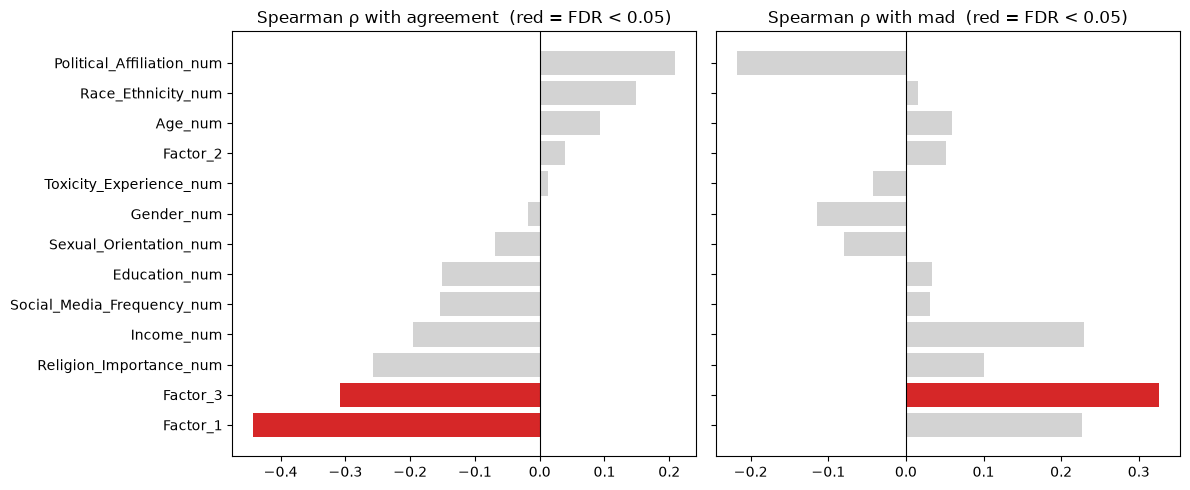

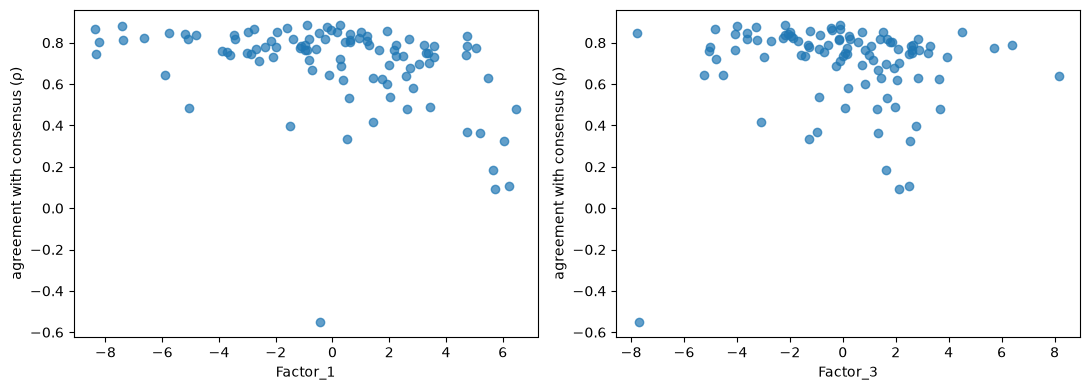

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
order = (profile_corr[profile_corr.target == 'agreement']
         .set_index('feature')['rho'].sort_values().index)
for ax, t in zip(axes, ['agreement', 'mad']):
    d = profile_corr[profile_corr.target == t].set_index('feature').loc[order]
    colors = ['tab:red' if s else 'lightgray' for s in d['significant']]
    ax.barh(d.index, d['rho'], color=colors)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'Spearman ρ with {t}  (red = FDR < 0.05)')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fig_profile_vs_agreement.png'), dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, f in zip(axes, ['Factor_1', 'Factor_3']):
    ax.scatter(prof[f], prof['agreement'], alpha=0.7)
    ax.set_xlabel(f); ax.set_ylabel('agreement with consensus (ρ)')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fig_factors_vs_agreement.png'), dpi=150)
plt.show()

## Part B — Linguistic features of prompts (ELFEN)

ELFEN (Maurer, 2025) extracts interpretable linguistic features with a spaCy backbone. We use the groups that are meaningful for short prompts: **surface, POS, emotion** (NRC sentiment, VAD, emotion intensity), **psycholinguistic** (concreteness, age of acquisition, prevalence, socialness, sensorimotor, iconicity), **readability, semantic** (hedges, synsets) and **entities**. Lexical-richness and dependency-type counts are skipped: prompts are one or two sentences long, so these are mostly noise.

Count features (`n_*`) are normalized by the number of tokens so that longer prompts don't dominate. Extraction is cached to `outputs/elfen_features.csv`; lexicons are downloaded automatically on the first run.

In [31]:
ELFEN_CACHE = os.path.join(OUT, 'elfen_features.csv')
GROUPS = ['surface', 'pos', 'psycholinguistic', 'readability', 'semantic', 'entities']

if os.path.exists(ELFEN_CACHE):
    elfen_df = pd.read_csv(ELFEN_CACHE)
    print('Loaded cached ELFEN features:', elfen_df.shape)
else:
    import polars as pl
    from elfen.extractor import Extractor
    from elfen.configs.extractor_config import CONFIG_ALL

    config = dict(CONFIG_ALL)
    config['text_column'] = 'Question_Content'

    try:
        config['features'] = {g: CONFIG_ALL['features'][g] for g in ['surface', 'pos', 'emotion', 'psycholinguistic', 'readability', 'semantic', 'entities']}
        text_df = pl.from_pandas(prompts[['Question_Index', 'Question_Content']])
        extractor = Extractor(data=text_df, config=config)
        extractor.extract_features()
        extractor.token_normalize()
        feat_names = sorted(extractor.get_feature_names())
        elfen_df = extractor.get_data().select(['Question_Index'] + feat_names).to_pandas()
        elfen_df.to_csv(ELFEN_CACHE, index=False)
        print('Extracted ELFEN features:', elfen_df.shape)
    except FileNotFoundError:
        print('ELFEN emotion lexicon missing; retrying without the emotion group.')
        config['features'] = {g: CONFIG_ALL['features'][g] for g in ['surface', 'pos', 'psycholinguistic', 'readability', 'semantic', 'entities']}
        text_df = pl.from_pandas(prompts[['Question_Index', 'Question_Content']])
        extractor = Extractor(data=text_df, config=config)
        extractor.extract_features()
        extractor.token_normalize()
        feat_names = sorted(extractor.get_feature_names())
        elfen_df = extractor.get_data().select(['Question_Index'] + feat_names).to_pandas()
        elfen_df.to_csv(ELFEN_CACHE, index=False)
        print('Extracted ELFEN features without emotion lexicon:', elfen_df.shape)

Extracting raw_sequence_length...
Extracting n_tokens...
Extracting n_sentences...
Extracting n_tokens_per_sentence...
Extracting n_characters...
Extracting avg_word_length...
Extracting n_types...
Extracting n_long_words...
Extracting n_lemmas...
Extracting n_lexical_tokens...
Extracting pos_variability...
Extracting n_per_pos...
Extracting sentiment_score...
ELFEN emotion lexicon missing; retrying without the emotion group.
Extracting raw_sequence_length...
Extracting n_tokens...
Extracting n_sentences...
Extracting n_tokens_per_sentence...
Extracting n_characters...
Extracting avg_word_length...
Extracting n_types...
Extracting n_long_words...
Extracting n_lemmas...
Extracting n_lexical_tokens...
Extracting pos_variability...
Extracting n_per_pos...
Extracting avg_concreteness...
Extracting n_low_concreteness...
Extracting n_high_concreteness...
Extracting avg_sd_concreteness...
Extracting n_controversial_concreteness...
Extracting min_concreteness...
Extracting max_concreteness...


ValueError: WordNet not found for 'en'. Please download the appropriate WordNet.
Check download instructions at https://elfen.readthedocs.io/en/latest/installation.html#third-party-resources
Original error message from the 'wn' package: no lexicon found with lang='en' and lexicon='*'

In [ ]:
# Clean: keep numeric columns, drop features that are (almost) constant or mostly missing
X_ling = elfen_df.set_index('Question_Index').apply(pd.to_numeric, errors='coerce')
X_ling = X_ling.replace([np.inf, -np.inf], np.nan)
X_ling = X_ling.loc[:, X_ling.isna().mean() < 0.2]
X_ling = X_ling.fillna(X_ling.median())
X_ling = X_ling.loc[:, X_ling.nunique() > 5]          # need variation across 150 prompts
X_ling = X_ling.loc[prompts['Question_Index']]
ELFEN_FEATS = list(X_ling.columns)
print(len(ELFEN_FEATS), 'ELFEN features kept')

**Targets (per prompt):**
- `std_rating` — standard deviation of the 100 annotators' ratings = **disagreement** (same measure as the contested-prompt analysis)
- `mean_rating` — average perceived harm, reported for comparison (a feature can relate to harm without relating to disagreement)

In [ ]:
targets = pd.DataFrame({
    'Question_Index': prompts['Question_Index'].values,
    'std_rating':  np.nanstd(R, axis=0, ddof=1),
    'mean_rating': np.nanmean(R, axis=0),
}).set_index('Question_Index')

ling = X_ling.join(targets)
ling_corr = corr_table(ling, ELFEN_FEATS, ['std_rating', 'mean_rating'])
ling_corr.to_csv(os.path.join(OUT, 'elfen_feature_correlations.csv'), index=False)

print('Significant after FDR:')
print(ling_corr[ling_corr.significant].groupby('target').size())
ling_corr[ling_corr.target == 'std_rating'].head(15).round(4)

In [ ]:
ling_corr[ling_corr.target == 'mean_rating'].head(15).round(4)

### Multivariate: do ELFEN features add predictive power?

Ridge regression on the **same prompt split and KFold** as the main report. We compare three feature sets for predicting disagreement (`std_rating`) and mean harm:
- **A** — SafetyAnalyst (`action_*`, `effect_*`), our strongest prompt-level category
- **L** — ELFEN linguistic features
- **A + L**

Features are standardized inside the pipeline (fit on training folds only), because ELFEN features have very different scales.

**Note on comparability with the main report:** the main report fits `Ridge(alpha=1.0)` on the *raw* SafetyAnalyst probabilities (Test R² ≈ 0.24 for mean harm). Raw probabilities are small numbers, so alpha=1 acts as strong regularization there. After standardization alpha=1 is much weaker and overfits with only 100 training prompts. We therefore report two model variants:
- `Ridge(alpha=1.0)` — the project convention
- `RidgeCV` — alpha chosen from a log grid using only the training data (inner CV), which is fairer when the number of features is large (A + L has ~200 features for 100 prompts)

In [ ]:
np.random.seed(42)
all_q = prompts['Question_Index'].values.copy()
np.random.shuffle(all_q)
train_q, test_q = all_q[:100], all_q[100:]

cat_A = [c for c in prompts.columns if c.startswith('action_') or c.startswith('effect_')]
X_all = prompts.set_index('Question_Index')[cat_A].join(X_ling)

FEATURE_SETS = {'A (SafetyAnalyst)': cat_A, 'L (ELFEN)': ELFEN_FEATS, 'A + L': cat_A + ELFEN_FEATS}

ALPHAS = np.logspace(-2, 4, 25)
MODELS = {
    'Ridge(alpha=1)': lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'RidgeCV':        lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)),
}

rows = []
for (target, (model_name, make_model)) in [(t, mm) for t in ['std_rating', 'mean_rating'] for mm in MODELS.items()]:
    y = targets[target]
    for name, cols in FEATURE_SETS.items():
        Xtr, ytr = X_all.loc[train_q, cols], y.loc[train_q]
        Xte, yte = X_all.loc[test_q, cols],  y.loc[test_q]
        cv_r2 = []
        for tr, va in KF.split(Xtr):
            m = make_model().fit(Xtr.iloc[tr], ytr.iloc[tr])
            cv_r2.append(r2_score(ytr.iloc[va], m.predict(Xtr.iloc[va])))
        m = make_model().fit(Xtr, ytr)
        p = m.predict(Xte)
        rows.append({'target': target, 'model': model_name, 'features': name, 'n_feats': len(cols),
                     'CV_R2': np.mean(cv_r2), 'CV_R2_sd': np.std(cv_r2),
                     'Test_R2': r2_score(yte, p), 'Test_MAE': mean_absolute_error(yte, p)})
model_res = pd.DataFrame(rows)
model_res.to_csv(os.path.join(OUT, 'elfen_model_comparison.csv'), index=False)
model_res.round(3)

### Most important ELFEN features

Permutation importance of the **L (ELFEN)** RidgeCV model on the held-out test prompts (drop in R² when a feature is shuffled, 50 repeats). We combine this with the univariate correlations: a feature is a robust finding if it is both FDR-significant and important in the model.

In [ ]:
imp_tables = {}
for target in ['std_rating', 'mean_rating']:
    y = targets[target]
    m = MODELS['RidgeCV']().fit(X_all.loc[train_q, ELFEN_FEATS], y.loc[train_q])
    pi = permutation_importance(m, X_all.loc[test_q, ELFEN_FEATS], y.loc[test_q],
                                scoring='r2', n_repeats=50, random_state=42)
    t = pd.DataFrame({'feature': ELFEN_FEATS,
                      'importance': pi.importances_mean,
                      'importance_sd': pi.importances_std})
    t = t.merge(ling_corr[ling_corr.target == target][['feature', 'rho', 'p_fdr']], on='feature')
    imp_tables[target] = t.sort_values('importance', ascending=False).reset_index(drop=True)
    imp_tables[target].to_csv(os.path.join(OUT, f'elfen_importance_{target}.csv'), index=False)

imp_tables['std_rating'].head(15).round(4)

In [ ]:
imp_tables['mean_rating'].head(15).round(4)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, target in zip(axes, ['std_rating', 'mean_rating']):
    d = ling_corr[ling_corr.target == target].head(15).iloc[::-1]
    colors = ['tab:red' if s else 'lightgray' for s in d['significant']]
    ax.barh(d['feature'], d['rho'], color=colors)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'Top 15 ELFEN features vs {target}\n(Spearman ρ, red = FDR < 0.05)')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fig_elfen_top_features.png'), dpi=150)
plt.show()

## Summary for the report

Fill in after running (all numbers are saved in `outputs/`):

- `profile_vs_agreement.csv` — which annotator profile features correlate with agreement / MAD
- `elfen_feature_correlations.csv` — univariate ELFEN results (FDR-corrected)
- `elfen_model_comparison.csv` — A vs L vs A+L
- `elfen_importance_*.csv` — most important ELFEN features

Interpretation caveats: 100 annotators and 150 prompts are small samples; correlations are associations, not causes; ELFEN lexicon features on one- or two-sentence prompts are based on few words and therefore noisy.